**Import Libraries**

In [ ]:
import tensorflow as tf
#from tensorflow.keras import datasets, layers, models
import keras
from keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

**Load Dataset**

In [ ]:
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

# Normalize pixel values to (0, 1)
x_train, x_test = x_train / 255.0, x_test / 255.0

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print("Training data shape: ", x_train.shape)
print("Training labels shape: ", y_train.shape)
print("Test data shape: ", x_test.shape)
print("Test labels shape: ", y_test.shape)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 796s 5us/step
Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000, 1)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000, 1)


**Display Sample Images**

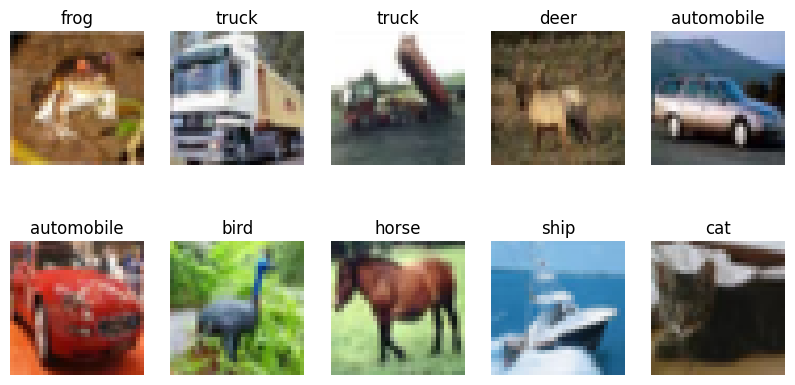

In [ ]:
plt.figure(figsize=(10,5))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')

plt.show()

**Build CNN Model**

In [ ]:
model = models.Sequential()

# First Convolution Block
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))

# Second Convolution Block
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))

# Third Convolution Block
model.add(layers.Conv2D(128, (3, 3), activation='relu'))

# Flatten Layer
model.add(layers.Flatten())

# Fully Connected Layers
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dropout(0.5))

# Output Layer
model.add(layers.Dense(10, activation='softmax'))

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

**Compile Model**

In [ ]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


**Train Model**

In [ ]:
history = model.fit(
      x_train,
      y_train,
      epochs=10,
      batch_size=64,
      validation_split=0.2,
      verbose=1
    )

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 92ms/step - accuracy: 0.3862 - loss: 1.6768 - val_accuracy: 0.5059 - val_loss: 1.3589
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 79s 87ms/step - accuracy: 0.5228 - loss: 1.3423 - val_accuracy: 0.5773 - val_loss: 1.2070
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 84s 90ms/step - accuracy: 0.5832 - loss: 1.1870 - val_accuracy: 0.6266 - val_loss: 1.0524
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 88s 99ms/step - accuracy: 0.6199 - loss: 1.0841 - val_accuracy: 0.6651 - val_loss: 0.9671
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 85s 104ms/step - accuracy: 0.6523 - loss: 0.9984 - val_accuracy: 0.6637 - val_loss: 0.9596
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 59s 94ms/step - accuracy: 0.6816 - loss: 0.9156 - val_accuracy: 0.6890 - val_loss: 0.8818
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 58s 92ms/step - accuracy: 0.7032 - loss: 0.8559 - val_accuracy: 0.7126 - val_loss: 0.8192
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 90ms/step - accuracy: 0.7204 - loss: 0.8098 -

**Plot Accuracy and Loss**

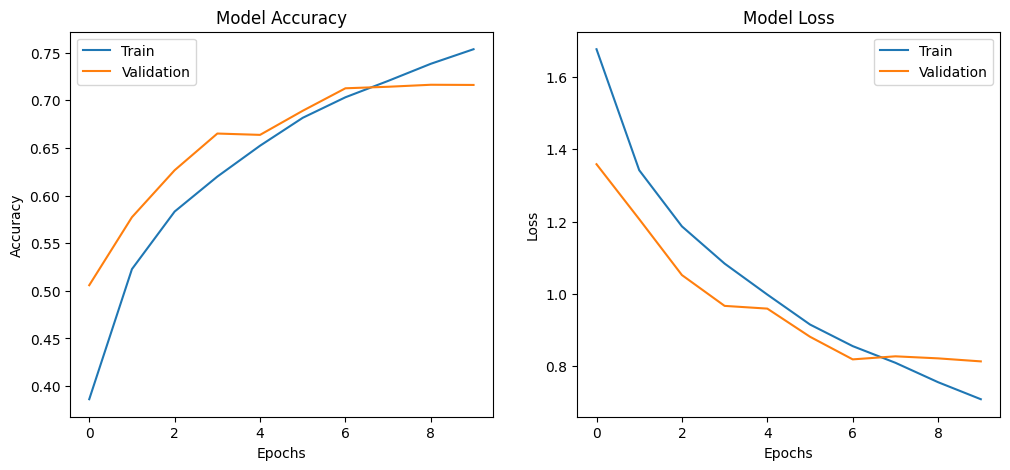

In [ ]:
plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

**Evaluate on Test Data**

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print("\nTest accuracy:", test_acc)
print("Test loss:", test_loss)

313/313 - 5s - 14ms/step - accuracy: 0.7128 - loss: 0.8358

Test accuracy: 0.7128000259399414
Test loss: 0.8358298540115356


**Prediction**

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step


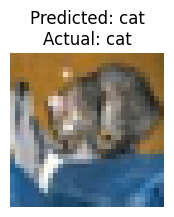

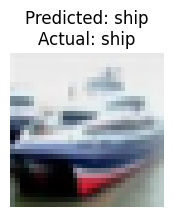

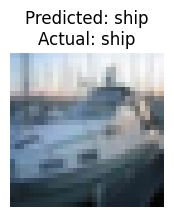

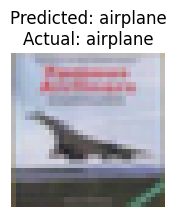

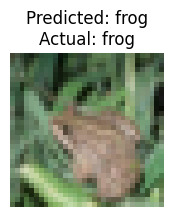

In [ ]:
predictions = model.predict(x_test)

for i in range(5):
    predicted_label = np.argmax(predictions[i])
    actual_label = y_test[i][0]

    plt.figure(figsize=(2,2))
    plt.imshow(x_test[i])
    plt.title(
        f"Predicted: {class_names[predicted_label]}\n"
        f"Actual: {class_names[actual_label]}"
    )

    plt.axis('off')
    plt.show()


**Confusion Matrix**

<Figure size 1000x800 with 0 Axes>

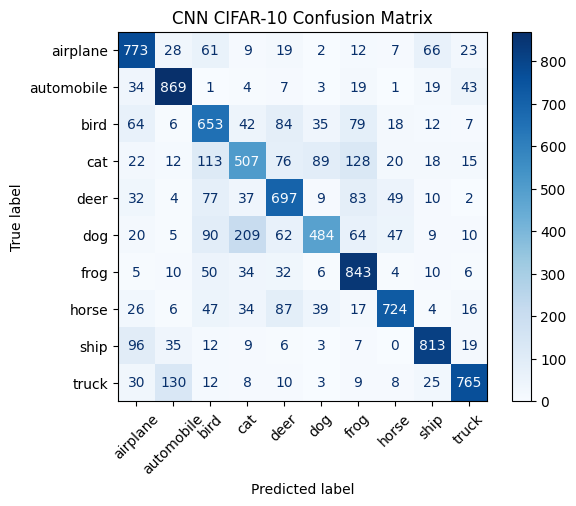

In [ ]:
# Predicted labels
y_pred = np.argmax(predictions, axis=1)

# True labels
y_true = y_test.flatten()

# Compute Confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Display confusion matrix
plt.figure(figsize=(10,8))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

disp.plot(cmap='Blues', xticks_rotation=45)

plt.title('CNN CIFAR-10 Confusion Matrix')
plt.show()
